# Projet · Application de suivi du diabète (FHIR)
**M2 Data Science en santé · Université de Lille · Armel Kanhonou**

Application Python de suivi du diabète pour **un patient**, construite uniquement sur des recherches FHIR R4 :
1. récupérer ses **dernières glycémies** ;
2. afficher son **traitement en cours** ;
3. tracer l'**évolution** de la glycémie, **unités harmonisées** en mg/dL.

Source : serveur public HAPI `https://hapi.fhir.org/baseR4`.

| Étape | Contenu |
|---|---|
| 0 | Configuration et fonctions d'accès FHIR (erreurs, pagination) |
| 1 | Création d'un patient de démonstration **fictif** (Bundle `transaction`) |
| 2 | L'application : Patient → Observation → MedicationRequest / MedicationStatement |
| 3 | Courbe `courbe_glycemie.png` |
| 4 | Tests de robustesse : Bundle vide, serveur injoignable, champs absents |

> ⚠️ Toutes les données envoyées sont **fictives**. Le serveur public est ouvert à tous : on n'y écrit jamais de données réelles.

## 0 · Configuration

In [1]:
import uuid
import requests
import pandas as pd
import matplotlib.pyplot as plt
from pydantic import ValidationError
from fhir.resources.R4B.patient import Patient
from fhir.resources.R4B.observation import Observation
from fhir.resources.R4B.medicationrequest import MedicationRequest
from fhir.resources.R4B.medicationstatement import MedicationStatement

BASE = "https://hapi.fhir.org/baseR4"          # serveur FHIR R4 public
H = {"Accept": "application/fhir+json"}
TIMEOUT = 30                                    # secondes

SYSTEME_ID = "urn:m2dss:kanhonou"               # système de l'identifiant du patient de démo
LOINC = "http://loinc.org"
CODES_GLYCEMIE = ["2345-7", "14749-6"]          # glucose en masse (mg/dL, g/L) et en moles (mmol/L)

# Harmonisation : facteur pour passer en mg/dL
CONVERSION_MG_DL = {"mg/dL": 1, "g/L": 100, "mmol/L": 18.016}   # glucose : 180,16 g/mol
SEUIL = 126                                     # mg/dL, glycémie à jeun (critère du diabète)
STATUTS_VALIDES = {"final", "amended", "corrected"}

COULEURS = {"mg/dL": "#2a78d6", "g/L": "#eb6834", "mmol/L": "#1baf7a"}
pd.set_option("display.width", 140)
print("Configuration OK · serveur :", BASE)

Configuration OK · serveur : https://hapi.fhir.org/baseR4


### Fonctions d'accès au serveur
- `get_fhir` : une requête GET ; transforme les problèmes (réseau, `OperationOutcome`, code HTTP) en une erreur **lisible** `ErreurFHIR`.
- `rechercher` : une recherche FHIR complète ; suit les liens `next` du Bundle (**pagination**) et renvoie une liste, **vide** si aucun résultat.

In [2]:
class ErreurFHIR(Exception):
    '''Erreur lisible : serveur injoignable, requête refusée ou réponse inattendue.'''


def get_fhir(url, params=None):
    try:
        r = requests.get(url, params=params, headers=H, timeout=TIMEOUT)
    except requests.RequestException as err:
        raise ErreurFHIR(f"Serveur injoignable ({url.split('?')[0]}) : {type(err).__name__}. "
                         "Vérifiez la connexion Internet ou l'adresse du serveur.") from None
    try:
        contenu = r.json()
    except ValueError:
        raise ErreurFHIR(f"Réponse non FHIR (HTTP {r.status_code}) pour {url}") from None
    if contenu.get("resourceType") == "OperationOutcome":       # le serveur explique son refus
        details = "; ".join(i.get("diagnostics", "?") for i in contenu.get("issue", []))
        raise ErreurFHIR(f"Requête refusée (HTTP {r.status_code}) : {details}")
    if not r.ok:
        raise ErreurFHIR(f"Erreur HTTP {r.status_code} pour {url}")
    return contenu


def rechercher(type_ressource, params, base=None, limite=500):
    '''Recherche FHIR avec pagination. Renvoie la liste des ressources trouvées (peut être vide).'''
    url = f"{base or BASE}/{type_ressource}"
    ressources, pages = [], 0
    while url and len(ressources) < limite:
        bundle = get_fhir(url, params)
        pages += 1
        ressources += [e["resource"] for e in bundle.get("entry", []) if "resource" in e]
        url = next((l.get("url") for l in bundle.get("link", []) if l.get("relation") == "next"), None)
        params = None                     # le lien 'next' contient déjà tous les paramètres
    print(f"  {type_ressource:20} {len(ressources):3} ressource(s) en {pages} page(s)")
    return ressources

## 1 · Créer le patient de démonstration (fictif)

Le serveur public contient peu de patients ayant **à la fois** des glycémies et un traitement.
On crée donc un patient fictif, en **une seule transaction** (tout est créé, ou rien) :
- un `Patient` (nom « M2DSS-Kanhonou », identifiant unique généré à chaque exécution) ;
- 9 glycémies sur un an, dans les **3 unités** des laboratoires (mg/dL et g/L en LOINC 2345-7, mmol/L en LOINC 14749-6), plus une mesure **annulée sans valeur** pour tester les champs absents ;
- un `MedicationRequest` actif (prescription de metformine, codée RxNorm et ATC) et un `MedicationStatement` (prise déclarée).

Les ressources sont d'abord **validées** avec `fhir.resources`. Dans le Bundle, le patient est désigné par un `urn:uuid` temporaire, que le serveur remplace par le vrai identifiant.

In [3]:
IDENTIFIANT = str(uuid.uuid4())             # identifiant unique : un nouveau patient à chaque exécution
ref_patient = f"urn:uuid:{uuid.uuid4()}"    # référence temporaire, interne au Bundle

patient_demo = {
    "resourceType": "Patient",
    "identifier": [{"system": SYSTEME_ID, "value": IDENTIFIANT}],
    "name": [{"use": "official", "family": "M2DSS-Kanhonou", "given": ["Démo"]}],
    "gender": "male",
    "birthDate": "1968-03-14",
}

# (date, valeur, unité, code LOINC) : glycémies à jeun, la metformine débute le 01/12/2025
mesures = [
    ("2025-10-06T08:15:00+02:00", 168,  "mg/dL",  "2345-7"),
    ("2025-11-03T07:50:00+01:00", 1.74, "g/L",    "2345-7"),
    ("2025-12-01T08:05:00+01:00", 9.1,  "mmol/L", "14749-6"),
    ("2026-01-12T08:30:00+01:00", 152,  "mg/dL",  "2345-7"),
    ("2026-02-16T07:45:00+01:00", 1.41, "g/L",    "2345-7"),
    ("2026-04-13T08:10:00+02:00", 7.3,  "mmol/L", "14749-6"),
    ("2026-06-15T08:20:00+02:00", 124,  "mg/dL",  "2345-7"),
    ("2026-08-24T07:55:00+02:00", 1.18, "g/L",    "2345-7"),
    ("2026-10-19T08:00:00+02:00", 6.4,  "mmol/L", "14749-6"),
]
AFFICHAGE_LOINC = {"2345-7": "Glucose [Mass/volume] in Serum or Plasma",
                   "14749-6": "Glucose [Moles/volume] in Serum or Plasma"}

def glycemie(date, valeur, unite, loinc):
    return {
        "resourceType": "Observation", "status": "final",
        "category": [{"coding": [{"system": "http://terminology.hl7.org/CodeSystem/observation-category",
                                  "code": "laboratory"}]}],
        "code": {"coding": [{"system": LOINC, "code": loinc, "display": AFFICHAGE_LOINC[loinc]}],
                 "text": "Glycémie à jeun"},
        "subject": {"reference": ref_patient},
        "effectiveDateTime": date,
        "valueQuantity": {"value": valeur, "unit": unite,
                          "system": "http://unitsofmeasure.org", "code": unite},
    }

observations = [glycemie(*m) for m in mesures]
# Mesure annulée : pas de valeur, seulement une raison d'absence (doit être écartée par l'application)
observations.append({
    "resourceType": "Observation", "status": "cancelled",
    "code": {"coding": [{"system": LOINC, "code": "2345-7"}], "text": "Glycémie à jeun"},
    "subject": {"reference": ref_patient},
    "effectiveDateTime": "2026-09-14T08:00:00+02:00",
    "dataAbsentReason": {"coding": [{"system": "http://terminology.hl7.org/CodeSystem/data-absent-reason",
                                     "code": "not-performed"}]},
})

metformine = {
    "coding": [{"system": "http://www.nlm.nih.gov/research/umls/rxnorm", "code": "6809", "display": "metformin"},
               {"system": "http://www.whocc.no/atc", "code": "A10BA02", "display": "metformin"}],
    "text": "Metformine 1000 mg, comprimé",
}
prescription = {
    "resourceType": "MedicationRequest", "status": "active", "intent": "order",
    "medicationCodeableConcept": metformine,
    "subject": {"reference": ref_patient},
    "authoredOn": "2025-12-01",
    "requester": {"display": "Dr Démo (médecin fictif)"},
    "reasonCode": [{"coding": [{"system": "http://snomed.info/sct", "code": "44054006",
                                "display": "Diabetes mellitus type 2"}]}],
    "dosageInstruction": [{"text": "1 comprimé matin et soir, au cours des repas"}],
}
prise_declaree = {
    "resourceType": "MedicationStatement", "status": "active",
    "medicationCodeableConcept": metformine,
    "subject": {"reference": ref_patient},
    "effectivePeriod": {"start": "2025-12-02"},
    "dosage": [{"text": "1 comprimé matin et soir"}],
}

# Validation de la structure avant envoi
modeles = {"Patient": Patient, "Observation": Observation,
           "MedicationRequest": MedicationRequest, "MedicationStatement": MedicationStatement}
ressources_demo = [patient_demo, *observations, prescription, prise_declaree]
try:
    for res in ressources_demo:
        modeles[res["resourceType"]].model_validate(res)
    print(len(ressources_demo), "ressources valides")
except ValidationError as err:
    print("Ressource invalide :", err)

13 ressources valides


In [4]:
# Bundle transaction : le Patient d'abord (fullUrl = référence temporaire), puis tout ce qui le cite
tx = {"resourceType": "Bundle", "type": "transaction", "entry": [
    {"fullUrl": ref_patient if res is patient_demo else f"urn:uuid:{uuid.uuid4()}",
     "resource": res,
     "request": {"method": "POST", "url": res["resourceType"]}}
    for res in ressources_demo
]}

creation_ok = False
try:
    r = requests.post(BASE, json=tx, timeout=TIMEOUT,
                      headers={**H, "Content-Type": "application/fhir+json"})
    reponse = r.json()
    if r.ok and reponse.get("type") == "transaction-response":
        creation_ok = True
        lieux = [e["response"]["location"].split("/_history")[0] for e in reponse["entry"]]
        print(f"Transaction acceptée (HTTP {r.status_code}) : {len(lieux)} ressources créées")
        print("Patient créé :", lieux[0], "· identifiant", IDENTIFIANT)
    else:
        print(f"Transaction refusée (HTTP {r.status_code}) :",
              [i.get("diagnostics") for i in reponse.get("issue", [])])
except requests.RequestException as err:
    print("Serveur injoignable, patient de démonstration non créé :", type(err).__name__)
except ValueError:
    print(f"Réponse non FHIR (HTTP {r.status_code})")

Transaction acceptée (HTTP 200) : 13 ressources créées
Patient créé : Patient/290540 · identifiant ccaa3e9d-fbd5-40ee-a3d7-2e43dc979556


---
## 2 · L'application de suivi

À partir d'ici, l'application ne connaît que **l'identifiant du patient** : tout le reste est obtenu par des **recherches FHIR**, comme le ferait une vraie application branchée sur l'entrepôt d'un hôpital.

| Besoin | Recherche FHIR |
|---|---|
| Retrouver le patient | `GET Patient?identifier=urn:m2dss:kanhonou\|<id>` |
| Dernières glycémies | `GET Observation?patient=Patient/<id>&code=http://loinc.org\|2345-7,http://loinc.org\|14749-6&_sort=-date&_count=5` |
| Traitement prescrit | `GET MedicationRequest?patient=Patient/<id>&status=active` |
| Traitement déclaré | `GET MedicationStatement?patient=Patient/<id>&status=active` |

`_count=5` est volontairement petit : avec 10 observations, le serveur répond en **plusieurs pages**, et la pagination est réellement utilisée.

### 2.1 · Retrouver le patient

In [5]:
def trouver_patient(identifiant, base=None):
    '''Renvoie la ressource Patient correspondant à l'identifiant, ou None si aucun patient.'''
    patients = rechercher("Patient", {"identifier": f"{SYSTEME_ID}|{identifiant}"}, base=base)
    if not patients:
        print(f"  Aucun patient avec l'identifiant {identifiant} (Bundle vide).")
        return None
    if len(patients) > 1:
        print(f"  Attention : {len(patients)} patients portent cet identifiant, on garde le premier.")
    return patients[0]


def nom_complet(patient):
    noms = patient.get("name") or [{}]
    nom = next((n for n in noms if n.get("use") == "official"), noms[0])
    return " ".join([*nom.get("given", []), nom.get("family", "")]).strip() or "(nom non renseigné)"


patient_id = None
try:
    patient = trouver_patient(IDENTIFIANT)
    if patient:
        patient_id = patient["id"]
        print()
        print("Patient     :", nom_complet(patient))
        print("Sexe        :", patient.get("gender", "non renseigné"))
        print("Naissance   :", patient.get("birthDate", "non renseignée"))
        print("Id FHIR     :", f"Patient/{patient_id}")
except ErreurFHIR as err:
    print("⚠", err)

  Patient                1 ressource(s) en 1 page(s)

Patient     : Démo M2DSS-Kanhonou
Sexe        : male
Naissance   : 1968-03-14
Id FHIR     : Patient/290540


### 2.2 · Dernières glycémies, harmonisées en mg/dL

Chaque Observation est **aplatie** en une ligne, en lisant chaque champ avec `.get()` : un champ absent donne une valeur vide, sans planter.
Sont **écartées** (et comptées) : les mesures dont le statut n'est pas `final` / `amended` / `corrected`, celles sans valeur, et celles dans une unité inconnue.

In [6]:
def aplatir_glycemie(obs):
    vq = obs.get("valueQuantity") or {}
    codes = [c.get("code") for c in (obs.get("code") or {}).get("coding", [])]
    return {
        "id": obs.get("id"),
        "date": obs.get("effectiveDateTime") or (obs.get("effectivePeriod") or {}).get("start"),
        "statut": obs.get("status"),
        "loinc": next((c for c in codes if c in CODES_GLYCEMIE), None),
        "valeur_source": vq.get("value"),
        "unite_source": vq.get("code") or vq.get("unit"),
    }


def glycemies_du_patient(pid, base=None):
    params = {"patient": f"Patient/{pid}",
              "code": ",".join(f"{LOINC}|{c}" for c in CODES_GLYCEMIE),
              "_sort": "-date", "_count": 5}
    obs = rechercher("Observation", params, base=base)
    colonnes = ["id", "date", "statut", "loinc", "valeur_source", "unite_source"]
    df = pd.DataFrame([aplatir_glycemie(o) for o in obs], columns=colonnes)

    # Filtres de qualité
    garder = (df["statut"].isin(STATUTS_VALIDES) & df["valeur_source"].notna()
              & df["unite_source"].isin(list(CONVERSION_MG_DL)) & df["date"].notna())
    if (~garder).any():
        print(f"  {int((~garder).sum())} mesure(s) écartée(s) :",
              df.loc[~garder, ["id", "statut", "valeur_source", "unite_source"]].to_dict("records"))
    df = df[garder].copy()

    # Harmonisation en mg/dL
    df["date"] = pd.to_datetime(df["date"], utc=True).dt.tz_convert("Europe/Paris")
    df["valeur_mg_dl"] = (df["valeur_source"].astype(float) * df["unite_source"].map(CONVERSION_MG_DL)).round(1)
    df[f"≥ {SEUIL}"] = df["valeur_mg_dl"] >= SEUIL
    return df.sort_values("date", ascending=False).reset_index(drop=True)


glycemies = pd.DataFrame()
if patient_id is None:
    print("Pas de patient : étape ignorée.")
else:
    try:
        glycemies = glycemies_du_patient(patient_id)
    except ErreurFHIR as err:
        print("⚠", err)

if glycemies.empty:
    print("Aucune glycémie exploitable pour ce patient.")
else:
    N_DERNIERES = 8
    tableau = glycemies.head(N_DERNIERES).assign(date=lambda d: d["date"].dt.strftime("%d/%m/%Y %H:%M"))
    print(f"\n{N_DERNIERES} dernières glycémies (sur {len(glycemies)} exploitables) :")
    display(tableau[["date", "valeur_source", "unite_source", "loinc", "valeur_mg_dl", f"≥ {SEUIL}"]])

  Observation           10 ressource(s) en 2 page(s)
  1 mesure(s) écartée(s) : [{'id': '290550', 'statut': 'cancelled', 'valeur_source': nan, 'unite_source': nan}]



8 dernières glycémies (sur 9 exploitables) :


,date,valeur_source,unite_source,loinc,valeur_mg_dl,≥ 126
0,19/10/2026 08:00,6.40,mmol/L,14749-6,115.3,False
1,24/08/2026 07:55,1.18,g/L,2345-7,118.0,False
2,15/06/2026 08:20,124.00,mg/dL,2345-7,124.0,False
3,13/04/2026 08:10,7.30,mmol/L,14749-6,131.5,True
4,16/02/2026 07:45,1.41,g/L,2345-7,141.0,True
5,12/01/2026 08:30,152.00,mg/dL,2345-7,152.0,True
6,01/12/2025 08:05,9.10,mmol/L,14749-6,163.9,True
7,03/11/2025 07:50,1.74,g/L,2345-7,174.0,True


**Contrôle de l'harmonisation** : la moyenne en mg/dL par unité d'origine doit rester du même ordre de grandeur. Une moyenne 100 fois trop petite trahirait une conversion oubliée.

In [7]:
if not glycemies.empty:
    display(glycemies.groupby("unite_source")
                     .agg(n=("valeur_mg_dl", "size"),
                          moyenne_source=("valeur_source", "mean"),
                          moyenne_mg_dl=("valeur_mg_dl", "mean"))
                     .round(1))

,n,moyenne_source,moyenne_mg_dl
unite_source,,,
g/L,3,1.4,144.3
mg/dL,3,148.0,148.0
mmol/L,3,7.6,136.9


### 2.3 · Traitement en cours

- **`MedicationRequest`** (`status=active`) : ce qui a été **prescrit**, avec la posologie ;
- **`MedicationStatement`** (`status=active`) : ce que le patient **déclare prendre**, en complément.

Le médicament peut être codé directement (`medicationCodeableConcept`) ou désigné par une référence vers une ressource `Medication` (`medicationReference`) : les deux cas sont gérés.

In [8]:
NOMS_SYSTEMES = {"http://www.nlm.nih.gov/research/umls/rxnorm": "RxNorm",
                 "http://www.whocc.no/atc": "ATC",
                 "http://snomed.info/sct": "SNOMED CT"}


def concept_medicament(ressource, base=None):
    '''Renvoie le CodeableConcept du médicament, en suivant medicationReference si besoin.'''
    if "medicationCodeableConcept" in ressource:
        return ressource["medicationCodeableConcept"]
    ref = (ressource.get("medicationReference") or {}).get("reference")
    if ref and not ref.startswith("#"):
        try:
            return get_fhir(f"{base or BASE}/{ref}").get("code") or {}
        except ErreurFHIR as err:
            print("  Médicament référencé illisible :", err)
    return {"text": (ressource.get("medicationReference") or {}).get("display")}


def libelle(concept):
    codings = concept.get("coding", [])
    nom = concept.get("text") or next((c.get("display") for c in codings if c.get("display")), None)
    codes = ", ".join(f"{NOMS_SYSTEMES.get(c.get('system'), c.get('system'))} {c.get('code')}"
                      for c in codings if c.get("code"))
    return nom or "(médicament non renseigné)", codes or "—"


def texte_posologie(dosages):
    return "; ".join(d.get("text", "") for d in (dosages or []) if d.get("text")) or "non renseignée"


def traitement_du_patient(pid, base=None):
    lignes = []
    for mr in rechercher("MedicationRequest", {"patient": f"Patient/{pid}", "status": "active"}, base=base):
        nom, codes = libelle(concept_medicament(mr, base))
        lignes.append({"source": "Prescription (MedicationRequest)", "médicament": nom, "codes": codes,
                       "posologie": texte_posologie(mr.get("dosageInstruction")),
                       "depuis": mr.get("authoredOn", "?")[:10],
                       "prescripteur": (mr.get("requester") or {}).get("display", "non renseigné"),
                       "statut": mr.get("status")})
    for ms in rechercher("MedicationStatement", {"patient": f"Patient/{pid}", "status": "active"}, base=base):
        nom, codes = libelle(concept_medicament(ms, base))
        debut = (ms.get("effectivePeriod") or {}).get("start") or ms.get("effectiveDateTime") or ms.get("dateAsserted") or "?"
        lignes.append({"source": "Prise déclarée (MedicationStatement)", "médicament": nom, "codes": codes,
                       "posologie": texte_posologie(ms.get("dosage")), "depuis": debut[:10],
                       "prescripteur": "—", "statut": ms.get("status")})
    return pd.DataFrame(lignes)


traitement = pd.DataFrame()
if patient_id is None:
    print("Pas de patient : étape ignorée.")
else:
    try:
        traitement = traitement_du_patient(patient_id)
    except ErreurFHIR as err:
        print("⚠", err)

if traitement.empty:
    print("Aucun traitement actif trouvé pour ce patient.")
else:
    print("\nTRAITEMENT EN COURS")
    for _, t in traitement.iterrows():
        print(f"• {t['médicament']}  [{t['codes']}]")
        print(f"    {t['source']} · depuis le {t['depuis']} · statut {t['statut']}")
        print(f"    Posologie : {t['posologie']} · Prescripteur : {t['prescripteur']}")

  MedicationRequest      1 ressource(s) en 1 page(s)


  MedicationStatement    1 ressource(s) en 1 page(s)

TRAITEMENT EN COURS
• Metformine 1000 mg, comprimé  [RxNorm 6809, ATC A10BA02]
    Prescription (MedicationRequest) · depuis le 2025-12-01 · statut active
    Posologie : 1 comprimé matin et soir, au cours des repas · Prescripteur : Dr Démo (médecin fictif)
• Metformine 1000 mg, comprimé  [RxNorm 6809, ATC A10BA02]
    Prise déclarée (MedicationStatement) · depuis le 2025-12-02 · statut active
    Posologie : 1 comprimé matin et soir · Prescripteur : —


---
## 3 · Courbe d'évolution (mg/dL)

Points colorés selon l'**unité d'origine** (donc le laboratoire), ligne pointillée au seuil de **126 mg/dL**, et début du traitement en vertical. La figure est enregistrée dans `courbe_glycemie.png`.

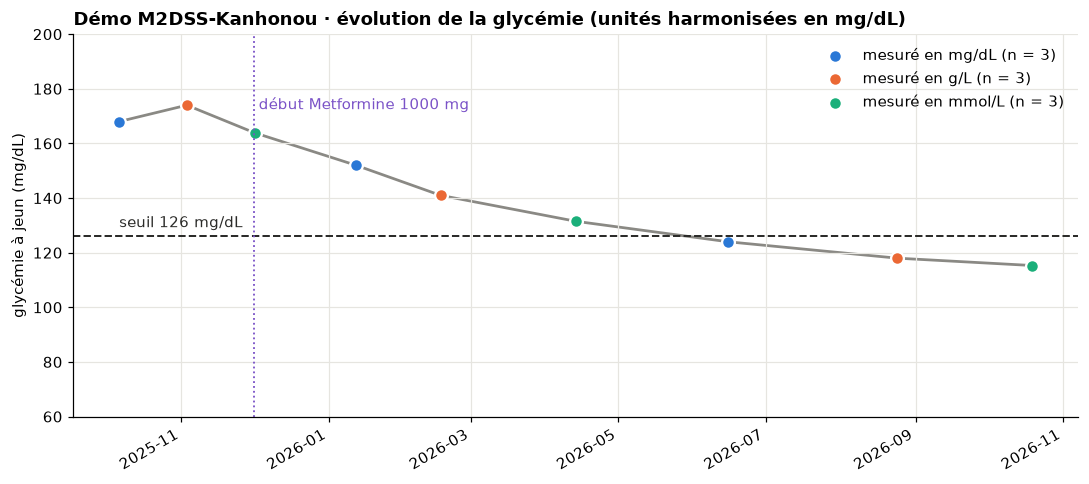

Courbe enregistrée : courbe_glycemie.png


In [9]:
FICHIER_COURBE = "courbe_glycemie.png"

if glycemies.empty:
    print("Pas de glycémie à tracer.")
else:
    d = glycemies.sort_values("date")
    fig, ax = plt.subplots(figsize=(10, 4.5), dpi=110)
    ax.plot(d["date"], d["valeur_mg_dl"], color="#8a8984", lw=1.8, zorder=1)
    for unite, couleur in COULEURS.items():
        s = d[d["unite_source"] == unite]
        if len(s):
            ax.scatter(s["date"], s["valeur_mg_dl"], s=70, color=couleur, edgecolors="white",
                       linewidths=1.5, zorder=2, label=f"mesuré en {unite} (n = {len(s)})")
    ax.axhline(SEUIL, color="#2b2b29", lw=1.3, ls="--")
    ax.text(d["date"].iloc[0], SEUIL + 2, f"seuil {SEUIL} mg/dL", color="#2b2b29", va="bottom")

    # Début du traitement prescrit, s'il est connu
    if not traitement.empty:
        presc = traitement[traitement["source"].str.startswith("Prescription")]
        if len(presc) and presc["depuis"].iloc[0] != "?":
            debut = pd.Timestamp(presc["depuis"].iloc[0], tz="Europe/Paris")
            ax.axvline(debut, color="#7a52c7", lw=1.2, ls=":")
            ax.text(debut, ax.get_ylim()[1], f" début {presc['médicament'].iloc[0].split(',')[0]}",
                    color="#7a52c7", va="top")

    ax.set_ylim(min(60, d["valeur_mg_dl"].min() - 10), max(200, d["valeur_mg_dl"].max() + 15))
    ax.set_ylabel("glycémie à jeun (mg/dL)")
    ax.set_title(f"{nom_complet(patient)} · évolution de la glycémie (unités harmonisées en mg/dL)",
                 loc="left", fontweight="bold")
    ax.grid(True, color="#e6e5e0")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="upper right", frameon=False)
    fig.autofmt_xdate()
    fig.tight_layout()
    fig.savefig(FICHIER_COURBE, dpi=150, bbox_inches="tight")
    plt.show()
    print("Courbe enregistrée :", FICHIER_COURBE)

---
## 4 · Tests de robustesse

L'application doit répondre proprement dans les cas difficiles, sans planter.

In [10]:
print("a) Bundle vide : identifiant qui n'existe pas")
try:
    print("   résultat :", trouver_patient("identifiant-qui-n-existe-pas"))
except ErreurFHIR as err:
    print("  ⚠", err)

print("\nb) Serveur injoignable : mauvaise adresse")
try:
    trouver_patient(IDENTIFIANT, base="http://localhost:9/fhir")
except ErreurFHIR as err:
    print("  ⚠", err)

print("\nc) Requête refusée par le serveur : paramètre de tri invalide")
try:
    rechercher("Observation", {"patient": "Patient/inconnu", "_sort": "parametre-inexistant"})
except ErreurFHIR as err:
    print("  ⚠", str(err)[:150])

print("\nd) Champs absents : Observation annulée, sans valeur ni unité")
print("  ", aplatir_glycemie({"resourceType": "Observation", "status": "cancelled"}))

a) Bundle vide : identifiant qui n'existe pas


  Patient                0 ressource(s) en 1 page(s)
  Aucun patient avec l'identifiant identifiant-qui-n-existe-pas (Bundle vide).
   résultat : None

b) Serveur injoignable : mauvaise adresse


  ⚠ Serveur injoignable (http://localhost:9/fhir/Patient) : ConnectionError. Vérifiez la connexion Internet ou l'adresse du serveur.

c) Requête refusée par le serveur : paramètre de tri invalide


  ⚠ Requête refusée (HTTP 400) : HAPI-1194: Unknown _sort parameter value "parametre-inexistant" for resource type "Observation" (Note: sort parameters va

d) Champs absents : Observation annulée, sans valeur ni unité
   {'id': None, 'date': None, 'statut': 'cancelled', 'loinc': None, 'valeur_source': None, 'unite_source': None}


---
## Synthèse

In [11]:
if patient_id and not glycemies.empty:
    derniere = glycemies.iloc[0]
    print(f"Patient            : {nom_complet(patient)} (Patient/{patient_id})")
    print(f"Glycémies          : {len(glycemies)} exploitables, du {glycemies['date'].min():%d/%m/%Y} au {glycemies['date'].max():%d/%m/%Y}")
    print(f"Dernière glycémie  : {derniere['valeur_mg_dl']} mg/dL le {derniere['date']:%d/%m/%Y} "
          f"(mesurée {derniere['valeur_source']} {derniere['unite_source']})")
    print(f"Au-dessus de {SEUIL}    : {int(glycemies[f'≥ {SEUIL}'].sum())} mesure(s) sur {len(glycemies)}")
    print(f"Traitement actif   : {', '.join(traitement['médicament'].unique()) if not traitement.empty else 'aucun'}")
else:
    print("Synthèse indisponible (serveur injoignable ou patient introuvable).")

Patient            : Démo M2DSS-Kanhonou (Patient/290540)
Glycémies          : 9 exploitables, du 06/10/2025 au 19/10/2026
Dernière glycémie  : 115.3 mg/dL le 19/10/2026 (mesurée 6.4 mmol/L)
Au-dessus de 126    : 6 mesure(s) sur 9
Traitement actif   : Metformine 1000 mg, comprimé
